<a href="https://colab.research.google.com/github/hubertwojcik/deep_learning/blob/main/4_rates_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from IPython import display
display.set_matplotlib_formats('svg')

/tmp/ipykernel_1101/2611213076.py:6: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  display.set_matplotlib_formats('svg')


# Create the data

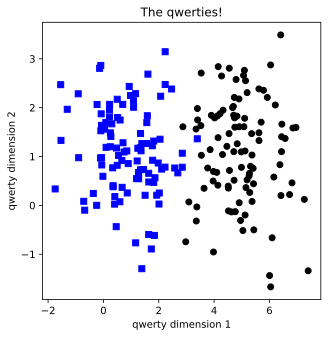

In [53]:
# create data
n_per_clust = 100
blur = 1

A = [ 1, 1]
B= [ 5, 1]

# generate data
a = [ A[0] + np.random.randn(n_per_clust) * blur, A[1] + np.random.randn(n_per_clust) * blur]
b = [B[0] + np.random.randn(n_per_clust) * blur, B[1] + np.random.randn(n_per_clust) * blur]

# true labels
labels_np = np.vstack((np.zeros((n_per_clust,1)), np.ones((n_per_clust, 1))))

#concatate into a trix
data_np = np.hstack((a,b)).T

# convert to a pytorch tensor
data = torch.tensor(data_np).float()
labels = torch.tensor(labels_np).float()

# show the data
fig = plt.figure(figsize=(5,5))
plt.plot(data[np.where(labels==0)[0],0],data[np.where(labels==0)[0],1],'bs')
plt.plot(data[np.where(labels==1)[0],0],data[np.where(labels==1)[0],1],'ko')
plt.title('The qwerties!')
plt.xlabel('qwerty dimension 1')
plt.ylabel('qwerty dimension 2')
plt.show()

# Build the model

In [54]:
def create_ann_model(learning_rate):
  # model
  ann_classify = nn.Sequential(
      nn.Linear(2, 1),
      nn.ReLU(),
      nn.Linear(1, 1),
      # nn.Sigmoid()
  )

  # loss
  loss_fun = nn.BCEWithLogitsLoss()

  # optimizer
  optimizer = torch.optim.SGD(ann_classify.parameters(), lr=learning_rate)

  # output
  return ann_classify, loss_fun, optimizer

# Training

In [55]:
num_epochs = 1000

def train_model(ann_model):
  losses = torch.zeros(num_epochs)

  # loop over epochs
  for epoch in range(num_epochs):
    y_hat = ann_model(data)

    #compute loss
    loss = loss_fun(y_hat, labels)
    losses[epoch] = loss

    # backprop
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  predictions = ann_model(data)

  # compute the predictions
  total_acc = 100 * torch.mean(((predictions > 0) == labels).float())

  return losses, predictions, total_acc

# Test the code in one run

Final accuracy: 98.5%
Final accuracy: 50%


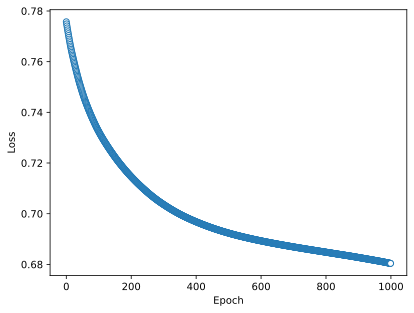

In [56]:
ann_classify, loss_fun, optimizer = create_ann_model(0.1)

losses, predictions, total_acc = train_model(ann_classify)

# print accuracy
print('Final accuracy: %g%%' %total_acc)



# create everything
ANNclassify,lossfun,optimizer = create_ann_model(.01)

# run it
losses,predictions,totalacc = train_model(ANNclassify)

# report accuracy
print('Final accuracy: %g%%' %totalacc)


# show the losses
plt.plot(losses.detach(),'o',markerfacecolor='w',linewidth=.1)
plt.xlabel('Epoch'), plt.ylabel('Loss')
plt.show()



# Experiment

In [57]:
learning_rates = np.linspace(.001,.1, 40)

# initizlaize output
acc_by_learning_rate = []
all_losses = np.zeros((len(learning_rates), num_epochs))

# loop through
for i, learning_rate in enumerate(learning_rates):

  # create and run the model
  ann_classify, loss_fun, optimizer = create_ann_model(learning_rate)

  # train model
  losses, predictions, total_acc = train_model(ann_classify)

  # store results
  acc_by_learning_rate.append(total_acc)
  all_losses[i, :] = losses.detach()

/tmp/ipykernel_1101/3016211366.py:18: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  all_losses[i, :] = losses.detach()


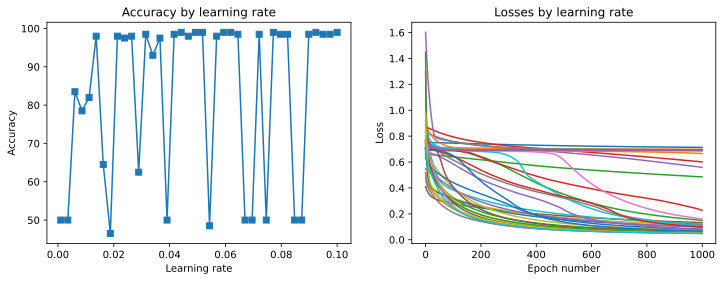

In [58]:
# plot the results
fig,ax = plt.subplots(1,2,figsize=(12,4))

ax[0].plot(learning_rates,acc_by_learning_rate,'s-')
ax[0].set_xlabel('Learning rate')
ax[0].set_ylabel('Accuracy')
ax[0].set_title('Accuracy by learning rate')

ax[1].plot(all_losses.T)
ax[1].set_title('Losses by learning rate')
ax[1].set_xlabel('Epoch number')
ax[1].set_ylabel('Loss')
plt.show()

In [59]:
# proportion of runs where the model had at least 70% accuracy
sum(torch.tensor(acc_by_learning_rate)>70)/len(acc_by_learning_rate)



tensor(0.7000)

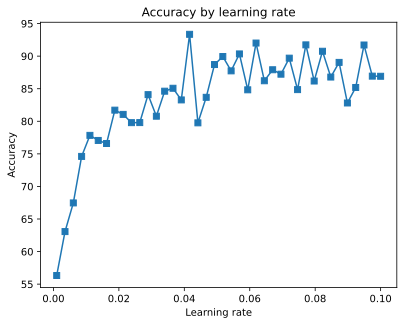

In [60]:
# run a "meta-experiment" by repeating the experiment N times
#  (different random weight initializations each time)

# number of times to iterate through the experiment
numExps = 50

# matrix to store all results
accMeta = np.zeros((numExps,len(learning_rates)))

# fewer epochs to reduce computation time
numepochs = 500

# now for the experiment
for expi in range(numExps):
  for i,lr in enumerate(learning_rates):

    # create and run the model
    ann_classify,lossfun,optimizer = create_ann_model(lr)
    losses,predictions,totalacc = train_model(ann_classify)

    # store the results
    accMeta[expi,i] = totalacc



# now plot the results, averaged over experiments
plt.plot(learning_rates,np.mean(accMeta,axis=0),'s-')
plt.xlabel('Learning rate')
plt.ylabel('Accuracy')
plt.title('Accuracy by learning rate')
plt.show()